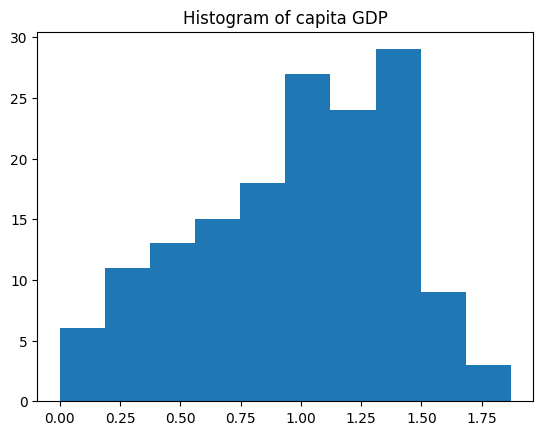

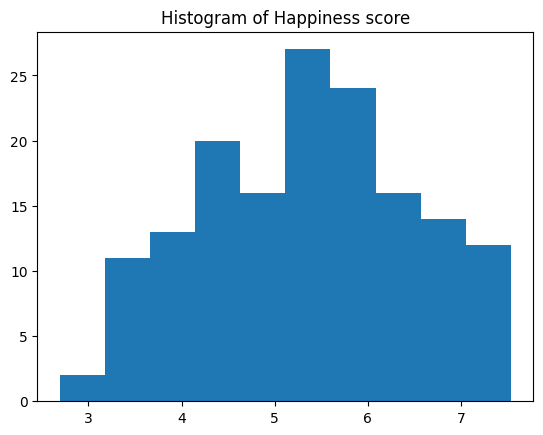

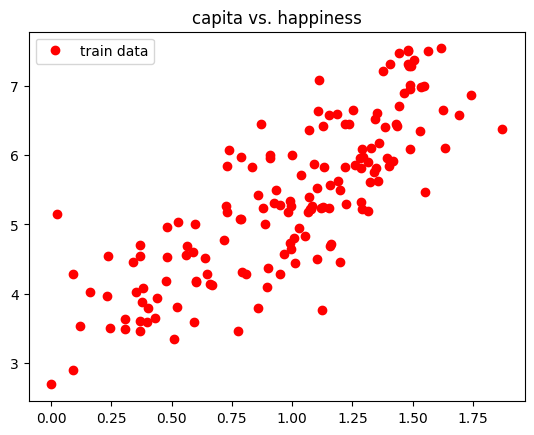

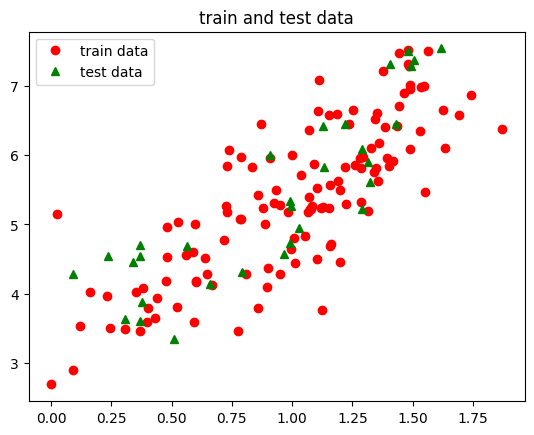

Model învățat: f(x) =  3.1999089795427924  +  2.1535833325615976  * x


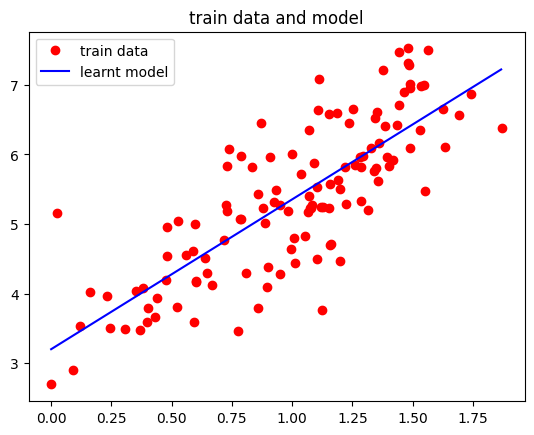

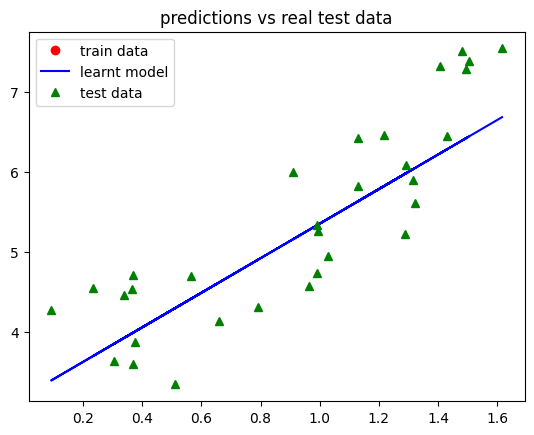

Eroare pe datele de test:  0.41319323170050337


In [20]:
from sklearn.linear_model import SGDRegressor
from MyMiniBatchGDRegression import MyMiniBatchGDRegression
import numpy as np
import matplotlib.pyplot as plt
import csv
import os
from sklearn.metrics import mean_squared_error

def loadData(fileName, inputVariabName, outputVariabName):
    data = []
    dataNames = []
    with open(fileName) as csv_file:
        csv_reader = csv.reader(csv_file, delimiter=',')
        line_count = 0
        for row in csv_reader:
            if line_count == 0:
                dataNames = row
            else:
                data.append(row)
            line_count += 1
    selectedVariable = dataNames.index(inputVariabName)
    inputs = [float(data[i][selectedVariable]) for i in range(len(data))]
    selectedOutput = dataNames.index(outputVariabName)
    outputs = [float(data[i][selectedOutput]) for i in range(len(data))]
    return inputs, outputs

def plotDataHistogram(x, variableName):
    n, bins, patches = plt.hist(x, 10)
    plt.title('Histogram of ' + variableName)
    plt.show()

def plotData(x1, y1, x2=None, y2=None, x3=None, y3=None, title=None):
    plt.plot(x1, y1, 'ro', label='train data')
    if x2:
        plt.plot(x2, y2, 'b-', label='learnt model')
    if x3:
        plt.plot(x3, y3, 'g^', label='test data')
    plt.title(title)
    plt.legend()
    plt.show()

def univariateRegression():
    crtDir = os.getcwd()
    filePath = os.path.join(crtDir, 'data', 'world-happiness-report-2017.csv')

    inputs, outputs = loadData(filePath, 'Economy..GDP.per.Capita.', 'Happiness.Score')

    plotDataHistogram(inputs, 'capita GDP')
    plotDataHistogram(outputs, 'Happiness score')

    plotData(inputs, outputs, [], [], [], [], 'capita vs. happiness')


    np.random.seed(5)
    indexes = [i for i in range(len(inputs))]
    trainSample = np.random.choice(indexes, int(0.8 * len(inputs)), replace=False)
    testSample = [i for i in indexes if i not in trainSample]
    trainInputs = [inputs[i] for i in trainSample]
    trainOutputs = [outputs[i] for i in trainSample]
    testInputs = [inputs[i] for i in testSample]
    testOutputs = [outputs[i] for i in testSample]

    plotData(trainInputs, trainOutputs, [], [], testInputs, testOutputs, "train and test data")


    xx = [[el] for el in trainInputs]

    regressor = MyMiniBatchGDRegression(learning_rate=0.01, no_epochs=1000, batch_size=16)
    regressor.fit(xx, trainOutputs)
    w0, w1 = regressor.intercept_, regressor.coef_[0]

    # regressor = SGDRegressor(
    #     learning_rate='constant',
    #     eta0=0.01,
    #     max_iter=1000,
    #     tol=None,
    #     shuffle=True
    # )
    # regressor.fit(xx, trainOutputs)
    #
    # w0 = regressor.intercept_[0]
    # w1 = regressor.coef_[0]

    print("Model învățat: f(x) = ", w0, " + ", w1, " * x")


    noOfPoints = 1000
    xref = []
    val = min(trainInputs)
    step = (max(trainInputs) - min(trainInputs)) / noOfPoints
    for i in range(1, noOfPoints):
        xref.append(val)
        val += step
    yref = [w0 + w1 * el for el in xref]
    plotData(trainInputs, trainOutputs, xref, yref, [], [], "train data and model")


    computedTestOutputs = regressor.predict([[x] for x in testInputs])
    plotData([], [], testInputs, computedTestOutputs, testInputs, testOutputs, "predictions vs real test data")


    error = mean_squared_error(testOutputs, computedTestOutputs)
    print("Eroare pe datele de test: ", error)


univariateRegression()



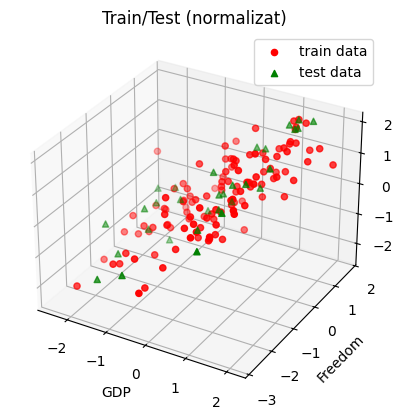

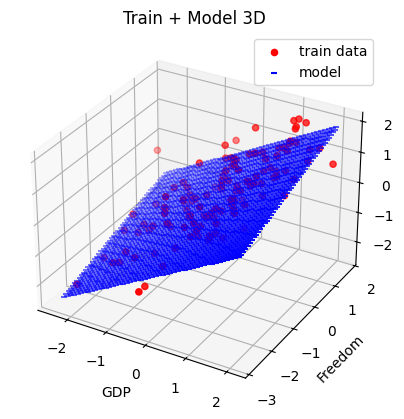

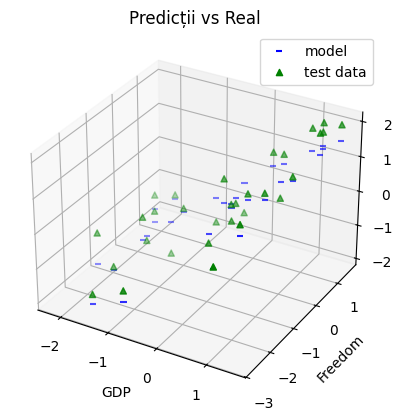

Eroare MSE pe setul de test: 0.2281


In [17]:
from MyMiniBatchGDRegression import MyMiniBatchGDRegression

def loadDataMoreInputs(fileName, inputVariabNames, outputVariabName):
    data = []
    dataNames = []
    with open(fileName) as csv_file:
        csv_reader = csv.reader(csv_file, delimiter=',')
        for i, row in enumerate(csv_reader):
            if i == 0:
                dataNames = row
            else:
                data.append(row)
    i1 = dataNames.index(inputVariabNames[0])
    i2 = dataNames.index(inputVariabNames[1])
    inputs = [[float(row[i1]), float(row[i2])] for row in data]
    i_out = dataNames.index(outputVariabName)
    outputs = [float(row[i_out]) for row in data]
    return inputs, outputs

def plot3Ddata(x1Train, x2Train, yTrain, x1Model=None, x2Model=None, yModel=None, x1Test=None, x2Test=None, yTest=None, title=None):
    ax = plt.axes(projection='3d')
    if x1Train:
        ax.scatter(x1Train, x2Train, yTrain, c='r', marker='o', label='train data')
    if x1Model:
        ax.scatter(x1Model, x2Model, yModel, c='b', marker='_', label='model')
    if x1Test:
        ax.scatter(x1Test, x2Test, yTest, c='g', marker='^', label='test data')
    ax.set_xlabel("GDP")
    ax.set_ylabel("Freedom")
    ax.set_zlabel("Happiness")
    plt.title(title)
    plt.legend()
    plt.show()


def computeMeanStd(data):
    no_features = len(data[0])
    mean = [0] * no_features
    std = [0] * no_features
    for j in range(no_features):
        values = [sample[j] for sample in data]
        mean[j] = np.mean(values)
        std[j] = np.std(values)
    return mean, std

def normalizeData(data, mean, std):
    # x_normalizat = (x - media) / deviația_standard
    norm = []
    for row in data:
        norm_row = [(row[i] - mean[i]) / std[i] if std[i] != 0 else row[i] for i in range(len(row))]
        norm.append(norm_row)
    return norm


def bivariateRegression():
    crtDir = os.getcwd()
    filePath = os.path.join(crtDir, 'data', 'world-happiness-report-2017.csv')
    inputs, outputs = loadDataMoreInputs(filePath, ['Economy..GDP.per.Capita.', 'Freedom'], 'Happiness.Score')


    np.random.seed(5)
    indexes = [i for i in range(len(inputs))]
    train_idx = np.random.choice(indexes, int(0.8 * len(inputs)), replace=False)
    test_idx = [i for i in indexes if i not in train_idx]

    trainInputs = [inputs[i] for i in train_idx]
    testInputs = [inputs[i] for i in test_idx]
    trainOutputs = [outputs[i] for i in train_idx]
    testOutputs = [outputs[i] for i in test_idx]


    mean, std = computeMeanStd(trainInputs)
    trainInputs = normalizeData(trainInputs, mean, std)
    testInputs = normalizeData(testInputs, mean, std)

    mean_out = np.mean(trainOutputs)
    std_out = np.std(trainOutputs)
    trainOutputs = [(y - mean_out) / std_out for y in trainOutputs]
    testOutputs = [(y - mean_out) / std_out for y in testOutputs]


    f1_train = [row[0] for row in trainInputs]
    f2_train = [row[1] for row in trainInputs]
    f1_test = [row[0] for row in testInputs]
    f2_test = [row[1] for row in testInputs]
    plot3Ddata(f1_train, f2_train, trainOutputs, [], [], [], f1_test, f2_test, testOutputs, "Train/Test (normalizat)")



    regressor = MyMiniBatchGDRegression(learning_rate=0.01, no_epochs=1000, batch_size=16)
    regressor.fit(trainInputs, trainOutputs)
    w0, w1, w2 = regressor.intercept_, regressor.coef_[0], regressor.coef_[1]

#     regressor = SGDRegressor(
#     learning_rate='constant',
#     eta0=0.01,
#     max_iter=1000,
#     tol=None,
#     shuffle=True
# )
#     regressor.fit(trainInputs, trainOutputs)
#     w0 = regressor.intercept_[0]
#     w1, w2 = regressor.coef_[0], regressor.coef_[1]
#     print(f"Model învățat: f(x) = {w0:.4f} + {w1:.4f}*GDP + {w2:.4f}*Freedom")


    xref1, xref2 = [], []
    val1, val2 = min(f1_train), min(f2_train)
    step1 = (max(f1_train) - min(f1_train)) / 50
    step2 = (max(f2_train) - min(f2_train)) / 50
    for i in range(1, 50):
        for j in range(1, 50):
            xref1.append(val1 + i * step1)
            xref2.append(val2 + j * step2)
    yref = [w0 + w1 * x1 + w2 * x2 for x1, x2 in zip(xref1, xref2)]
    plot3Ddata(f1_train, f2_train, trainOutputs, xref1, xref2, yref, [], [], [], "Train + Model 3D")


    computedTestOutputs = regressor.predict(testInputs)
    plot3Ddata([], [], [], f1_test, f2_test, computedTestOutputs, f1_test, f2_test, testOutputs, "Predicții vs Real")


    error = mean_squared_error(testOutputs, computedTestOutputs)
    print(f"Eroare MSE pe setul de test: {error:.4f}")


bivariateRegression()
